# ICDS Phase 4 — frozen paper artifacts

This notebook is a **read-only reporting layer** over the frozen Phase 4 scientific outputs. It verifies all frozen hashes before loading evidence. It does not fit models, produce predictions, alter features, tune thresholds, or overwrite Phase 4 artifacts.

In [1]:
from pathlib import Path
import csv, json, sys
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'IoT_auth_simulator').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'IoT_auth_simulator'))

from ml.icds.paper_artifacts import (
    PHASE4_TREE_FINGERPRINT, build_paper_artifacts, verify_and_load
)
PHASE4 = ROOT / 'artifacts/icds-ml-phase4'
OUTPUT = ROOT / 'artifacts/icds-paper-figures'

## A. Frozen artifact verification

In [2]:
evidence = verify_and_load(PHASE4)  # aborts on any mismatch
verification = {
    'artifact_tree_fingerprint': PHASE4_TREE_FINGERPRINT,
    'primary_runs': len(evidence.primary_metrics),
    'primary_predictions': evidence.primary_prediction_count,
    'grouped_runs': len(evidence.grouped_metrics),
    'grouped_predictions': evidence.grouped_prediction_count,
    'verified_source_hashes': evidence.source_hashes,
}
display(verification)

{'artifact_tree_fingerprint': 'sha256:cc100d1e234d8c0605639def25351d4c756e99a9b7b99acf3639c03065a97c11',
 'primary_runs': 45,
 'primary_predictions': 3780,
 'grouped_runs': 9,
 'grouped_predictions': 819,
 'verified_source_hashes': {'primary/predictions.jsonl': '04fc533592a50e23dab67ba22d3bd7ebf23239702de4a9daa149d586fbdc5539',
  'primary/run-provenance.json': '9a27f9ad469502b4dcd7d0408eff2788a877d51b96dd96751e434fe1343b2594',
  'primary/per-run-metrics.json': '50ee928098644035869dfb48306255b2f749c614111338f8b43445cbb79404aa',
  'primary/aggregate-summary.json': 'd33f909862039afd727250b67705c6359d974cde75849455c967efb8b70206ca',
  'grouped/predictions.jsonl': 'd76cb118f7d37082d2ee26e9cc90e79bd864875e65fdaca6b8820f04f931fb25',
  'grouped/run-provenance.json': 'bd560a4b8eac22e7778f11787449d0c57c32f6af3cf665e93525bf70d7089c13',
  'grouped/per-run-metrics.json': '7568feb63040978278cd202d63e8853197698054060cd25c011e4f780a25a687',
  'grouped/grouped-sensitivity-table.json': 'ef69601c1b57492b

## B. Load frozen evidence

Privileged scientific-role metadata is used only to stratify already-produced predictions for reporting; it is not detector input.

In [3]:
display({
    'primary_metric_records': len(evidence.primary_metrics),
    'primary_summary_models': sorted(evidence.primary_summary['by_model_condition']),
    'grouped_metric_records': len(evidence.grouped_metrics),
    'grouped_table_rows': len(evidence.grouped_table),
})

{'primary_metric_records': 45,
 'primary_summary_models': ['DT', 'LR', 'RF'],
 'grouped_metric_records': 9,
 'grouped_table_rows': 9}

## C–H. Deterministic figures, tables, and export

The generator below reads only the verified frozen evidence. Figure 2 uses two adjacent matrices rather than one heatmap because false-positive rates and recall have opposite scientific directionality. Figures retain repetition-level values wherever the primary design has repetitions. Tables are generated from the same in-memory records and exported as CSV and LaTeX fragments.

In [4]:
result = build_paper_artifacts(ROOT)
display(result)

Matplotlib is building the font cache; this may take a moment.


{'output_root': 'artifacts/icds-paper-figures',
 'manifest': 'artifacts/icds-paper-figures/paper-artifact-manifest.json',
 'figure_count': 4,
 'figure_export_count': 12,
 'table_count': 4,
 'table_export_count': 8,
 'primary_runs': 45,
 'primary_predictions': 3780,
 'grouped_runs': 9,
 'grouped_predictions': 819,
 'phase4_tree_fingerprint': 'sha256:cc100d1e234d8c0605639def25351d4c756e99a9b7b99acf3639c03065a97c11'}

### C. Main result — semantic hard-negative effect
Five repetition points are shown for each model, subgroup, and condition; diamonds and error bars are the frozen median and IQR.

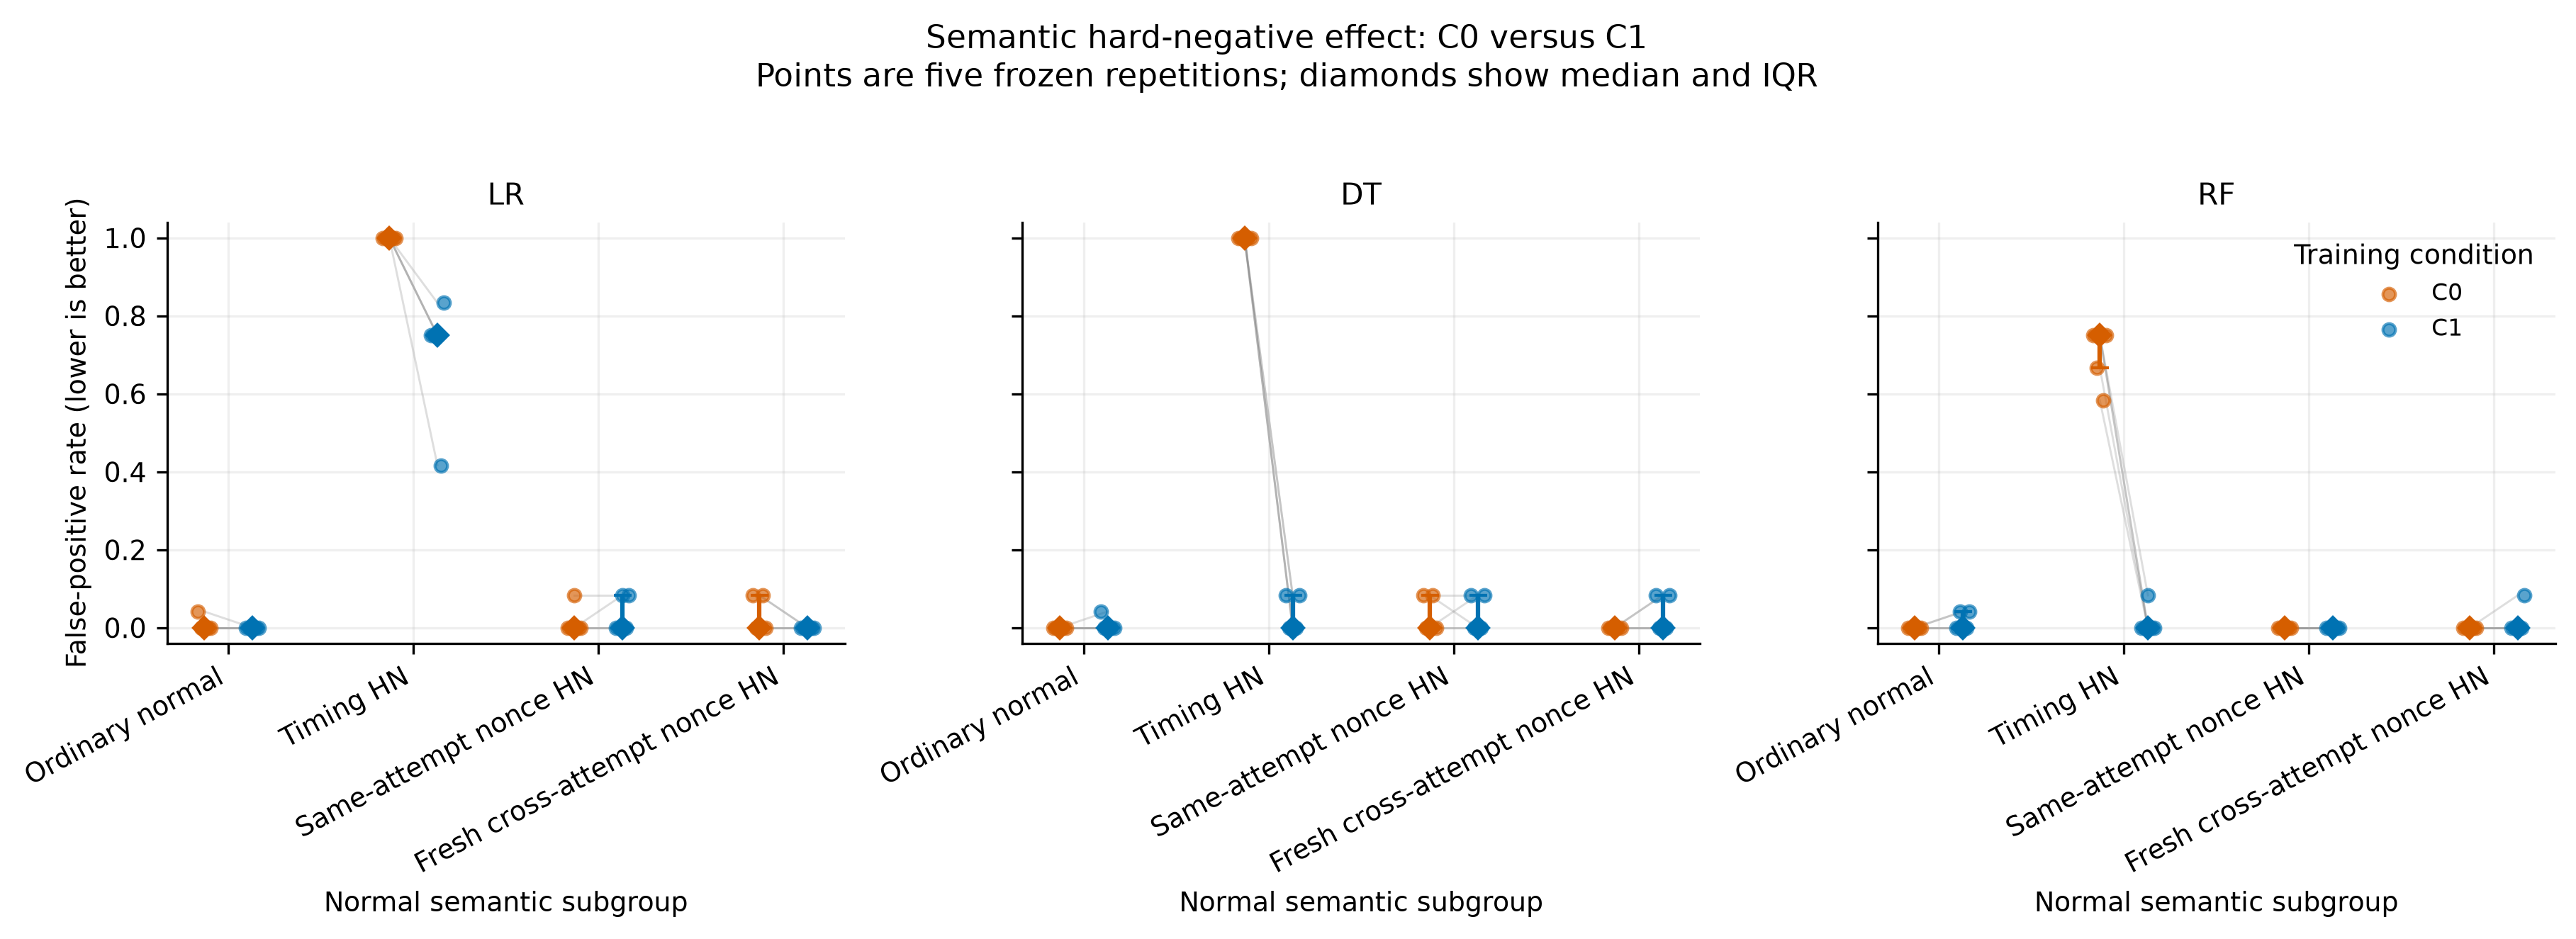

In [5]:
display(Image(filename=str(OUTPUT / 'figure-1-primary-hard-negative-effect.png'), width=1100))

### D. Semantic error-profile matrix
FPR and recall occupy separate color matrices with explicit lower/higher-is-better labels; shared numerical bounds do not imply a shared scientific quantity.

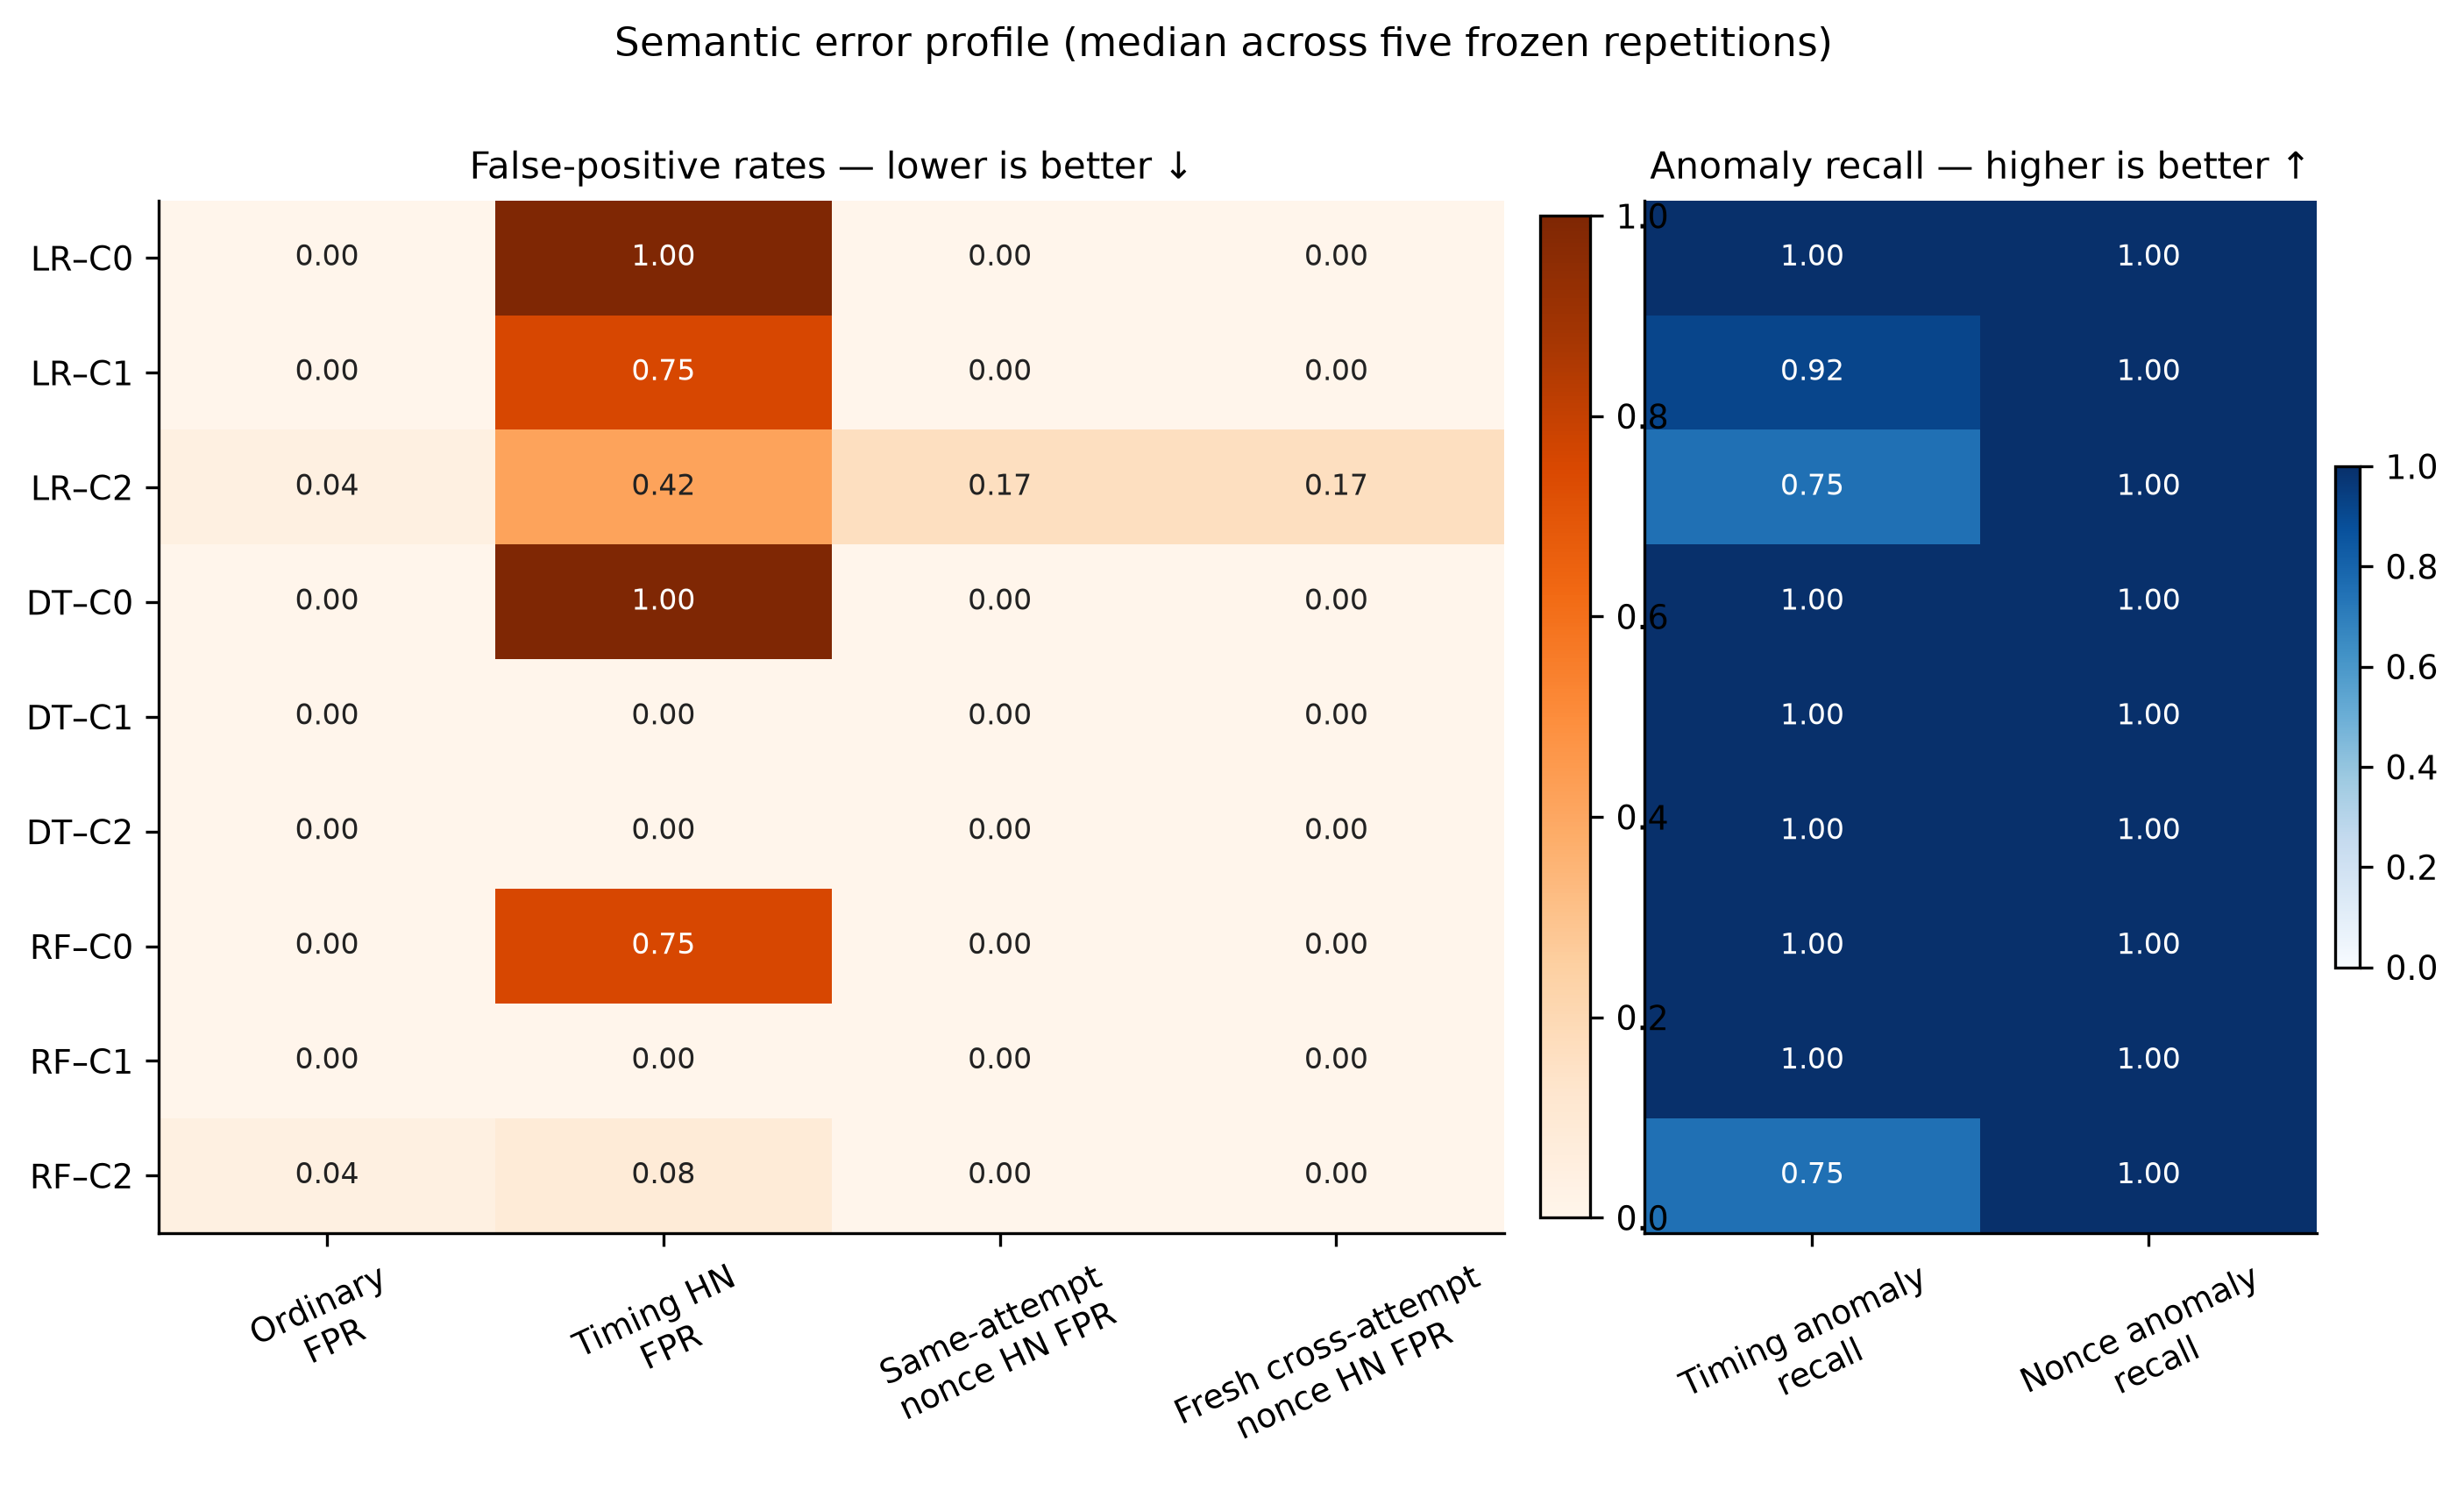

In [6]:
display(Image(filename=str(OUTPUT / 'figure-2-semantic-error-profile.png'), width=1000))

### E. C1 → C2 representation sensitivity
Interpretation is restricted to the frozen synthetic Timing/Nonce candidate, O03, complete-trace offline classification, and LR/DT/RF.

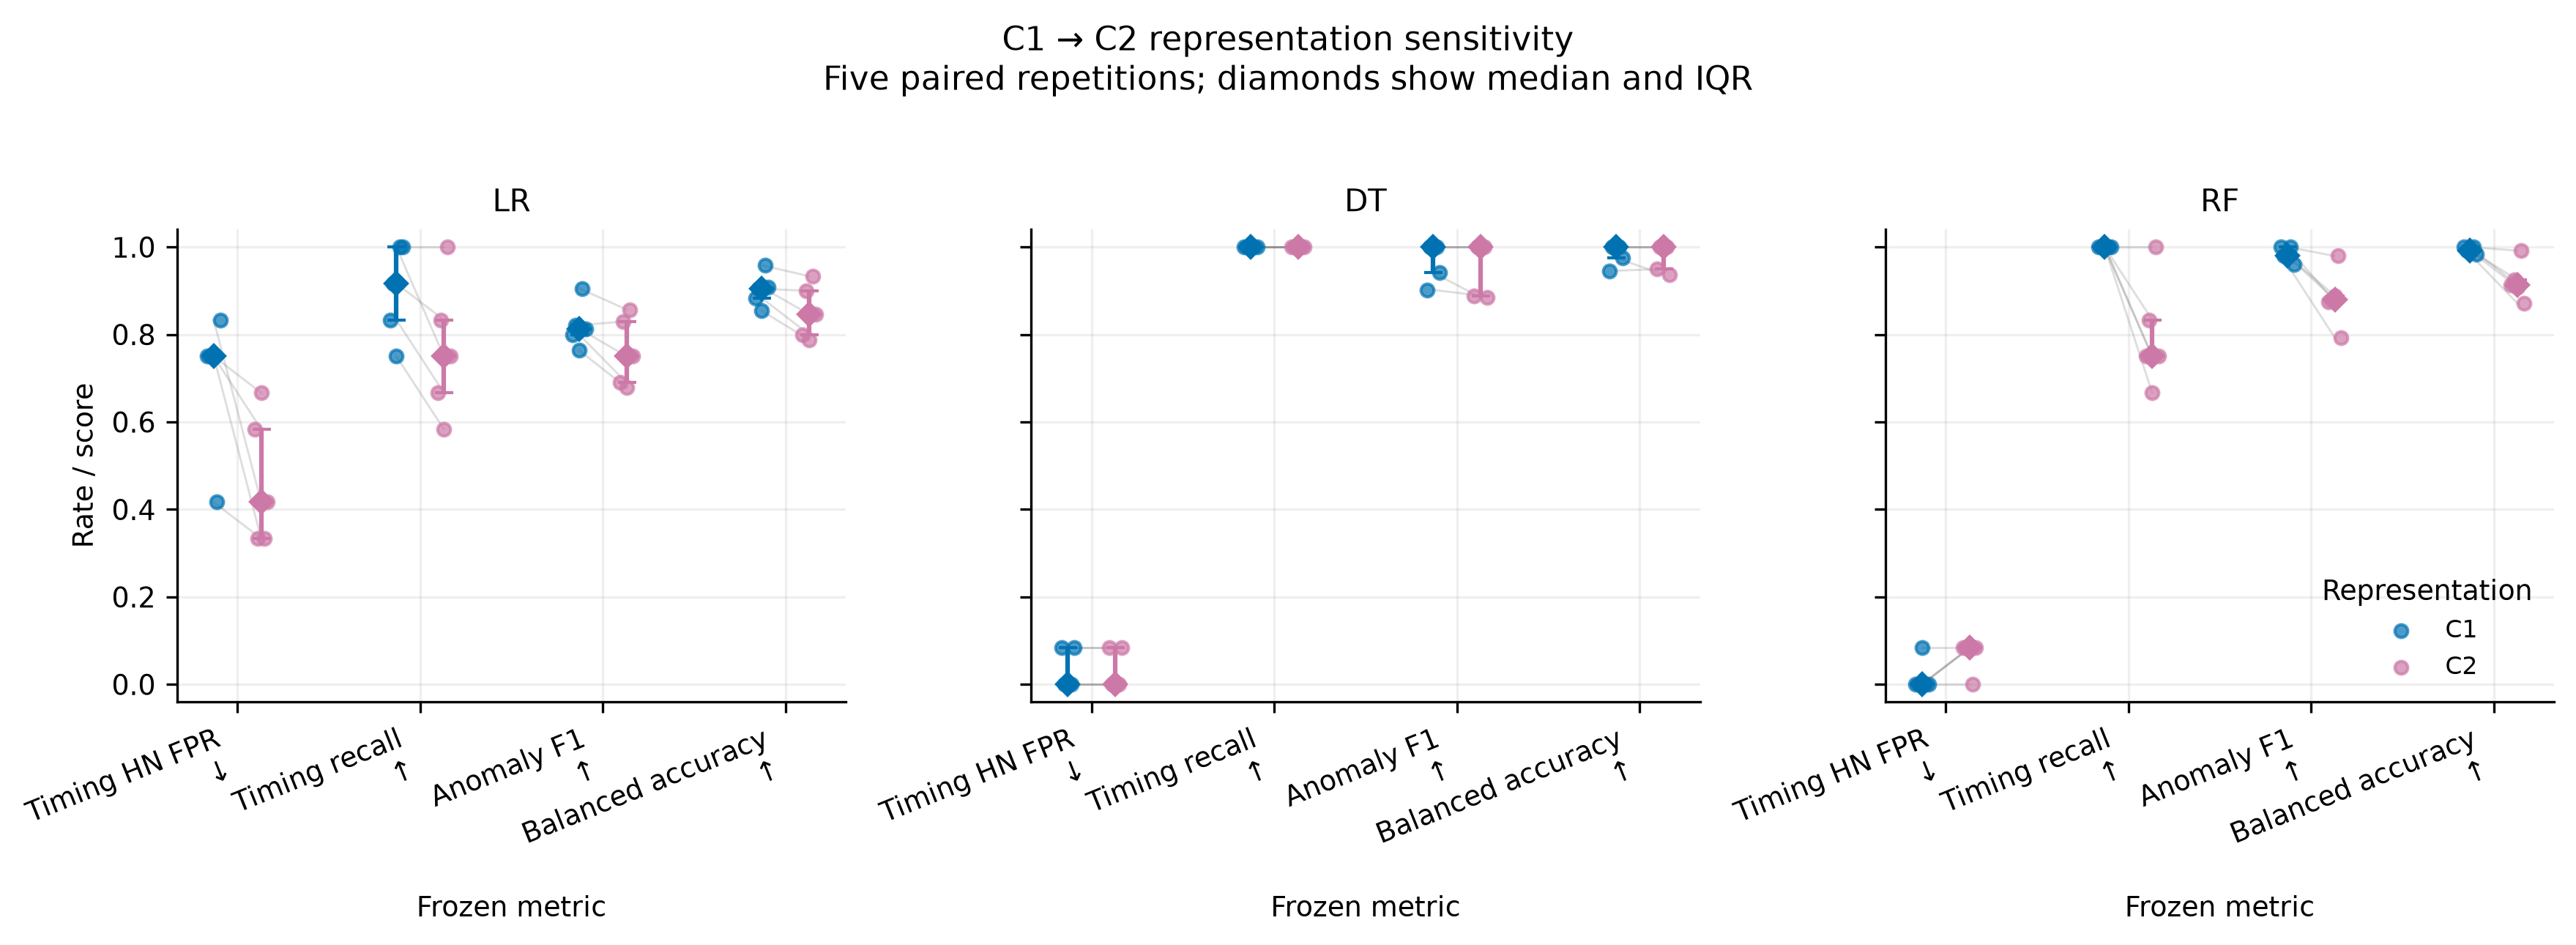

In [7]:
display(Image(filename=str(OUTPUT / 'figure-3-representation-sensitivity.png'), width=1100))

### F. Device-disjoint sensitivity — one controlled grouped partition
Raw counts are printed on bars. This descriptive sensitivity check is not population-level unseen-device generalization evidence.

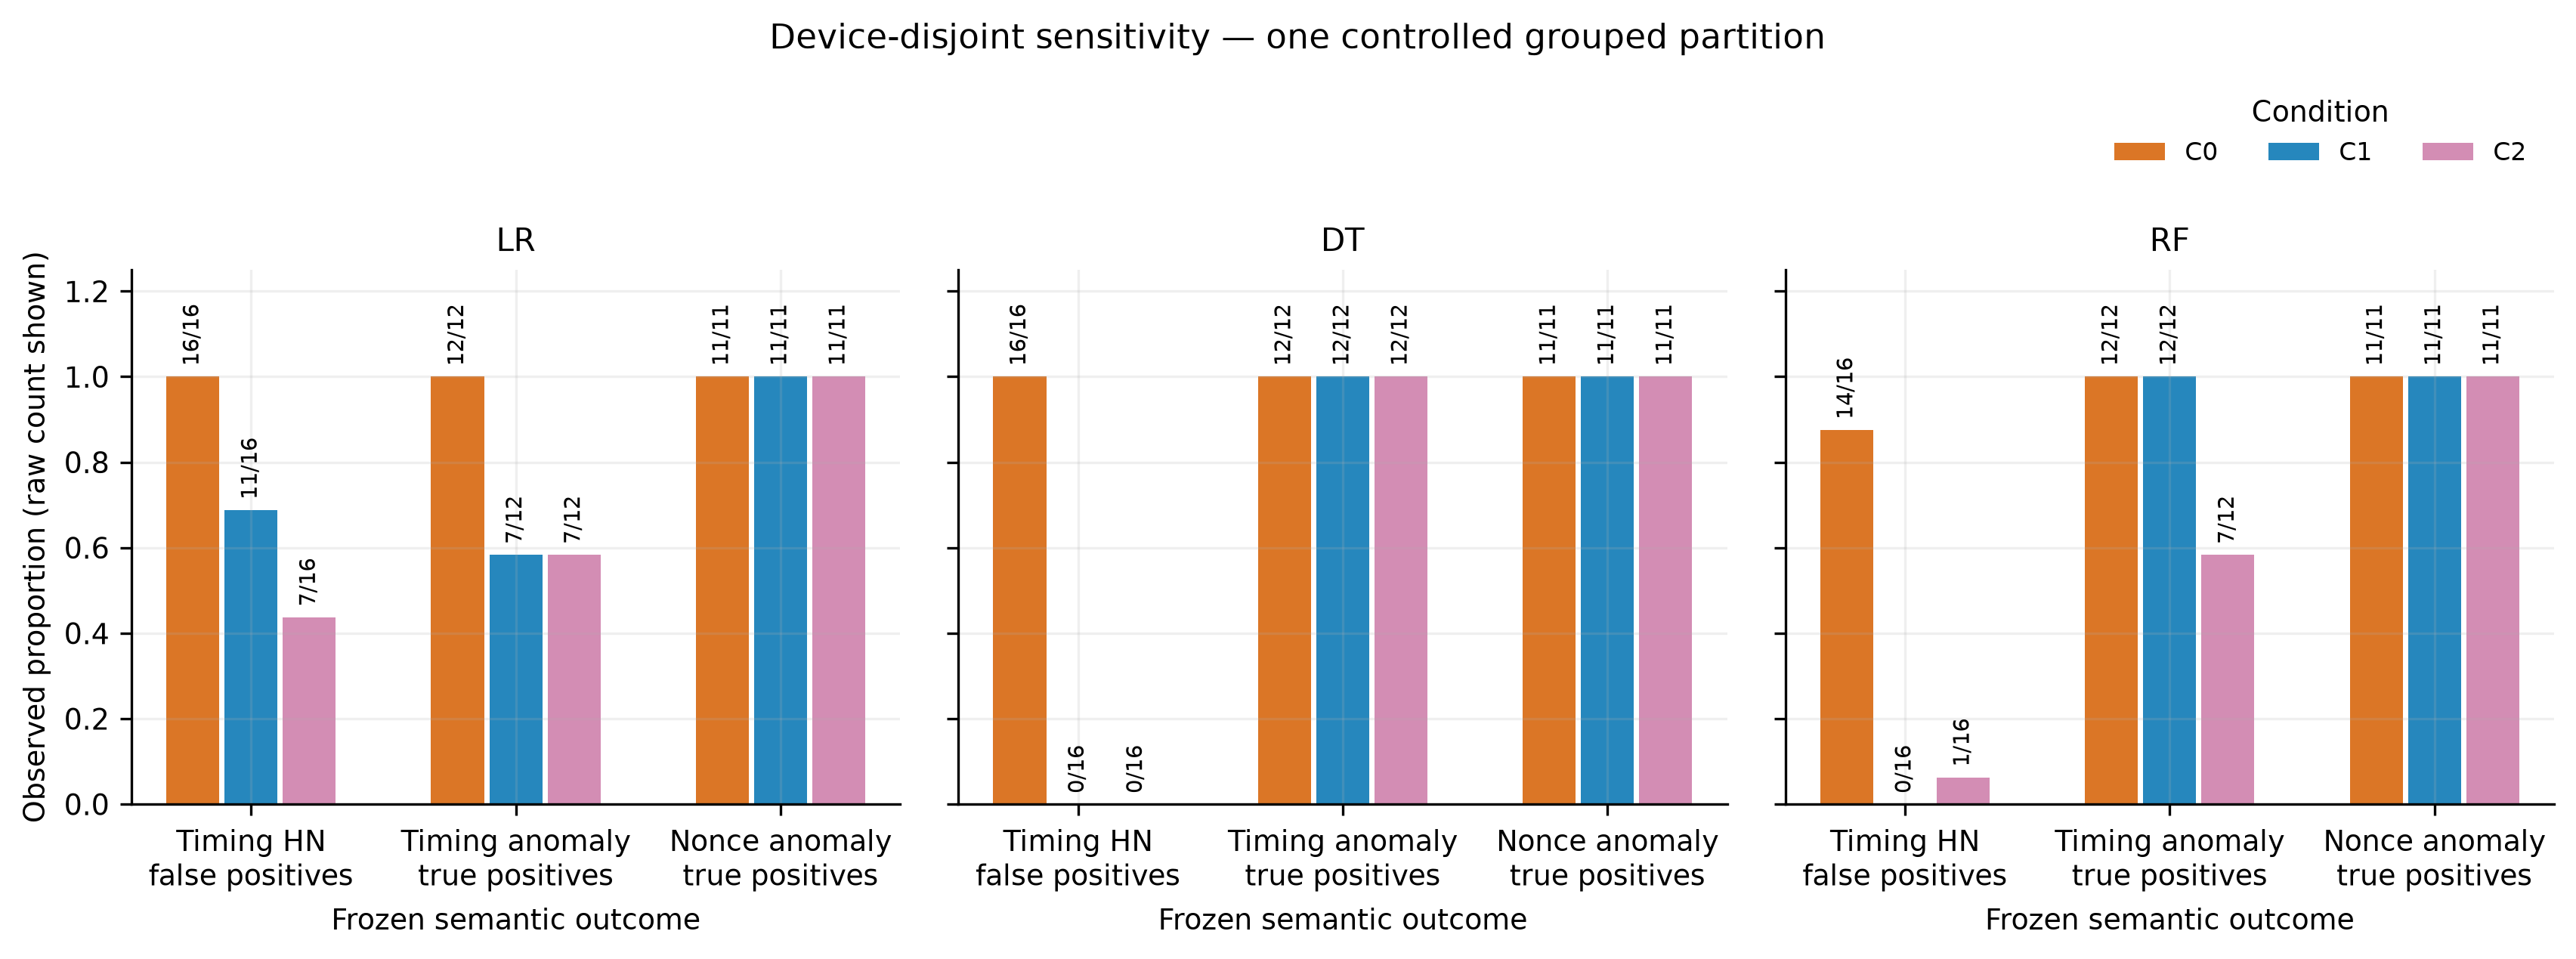

In [8]:
display(Image(filename=str(OUTPUT / 'figure-4-device-grouped-sensitivity.png'), width=1100))

### G. Paper tables

In [9]:
for filename in [
    'table-a-primary-performance.csv',
    'table-b-semantic-boundary.csv',
    'table-c-representation-sensitivity.csv',
    'table-d-device-grouped-sensitivity.csv',
]:
    with (OUTPUT / filename).open(newline='') as stream:
        rows = list(csv.DictReader(stream))
    display(Markdown(f'**{filename}**'))
    display(rows)

**table-a-primary-performance.csv**

[{'model': 'LR',
  'condition': 'C0',
  'anomaly_f1_median': '0.7868852459016393',
  'anomaly_f1_iqr': '0.013114754098360715',
  'anomaly_f1_median_iqr': '0.787 (0.013)',
  'balanced_accuracy_median': '0.8916666666666666',
  'balanced_accuracy_iqr': '0.008333333333333415',
  'balanced_accuracy_median_iqr': '0.892 (0.008)',
  'timing_recall_median': '1.0',
  'timing_recall_iqr': '0.0',
  'nonce_recall_median': '1.0',
  'nonce_recall_iqr': '0.0'},
 {'model': 'LR',
  'condition': 'C1',
  'anomaly_f1_median': '0.8135593220338984',
  'anomaly_f1_iqr': '0.021428571428571463',
  'anomaly_f1_median_iqr': '0.814 (0.021)',
  'balanced_accuracy_median': '0.9041666666666667',
  'balanced_accuracy_iqr': '0.025000000000000022',
  'balanced_accuracy_median_iqr': '0.904 (0.025)',
  'timing_recall_median': '0.9166666666666666',
  'timing_recall_iqr': '0.16666666666666663',
  'nonce_recall_median': '1.0',
  'nonce_recall_iqr': '0.0'},
 {'model': 'LR',
  'condition': 'C2',
  'anomaly_f1_median': '0.75',


**table-b-semantic-boundary.csv**

[{'model': 'LR',
  'c0_timing_hn_fpr_median': '1.0',
  'c0_timing_hn_fpr_iqr': '0.0',
  'c0_timing_hn_fpr_range': '1.000–1.000',
  'c0_timing_recall_median': '1.0',
  'c0_timing_recall_iqr': '0.0',
  'c0_timing_recall_range': '1.000–1.000',
  'c1_timing_hn_fpr_median': '0.75',
  'c1_timing_hn_fpr_iqr': '0.0',
  'c1_timing_hn_fpr_range': '0.417–0.833',
  'c1_timing_recall_median': '0.9166666666666666',
  'c1_timing_recall_iqr': '0.16666666666666663',
  'c1_timing_recall_range': '0.750–1.000'},
 {'model': 'DT',
  'c0_timing_hn_fpr_median': '1.0',
  'c0_timing_hn_fpr_iqr': '0.0',
  'c0_timing_hn_fpr_range': '1.000–1.000',
  'c0_timing_recall_median': '1.0',
  'c0_timing_recall_iqr': '0.0',
  'c0_timing_recall_range': '1.000–1.000',
  'c1_timing_hn_fpr_median': '0.0',
  'c1_timing_hn_fpr_iqr': '0.08333333333333333',
  'c1_timing_hn_fpr_range': '0.000–0.083',
  'c1_timing_recall_median': '1.0',
  'c1_timing_recall_iqr': '0.0',
  'c1_timing_recall_range': '1.000–1.000'},
 {'model': 'RF',
  '

**table-c-representation-sensitivity.csv**

[{'model': 'LR',
  'c1_timing_hn_fpr_median': '0.75',
  'c1_timing_hn_fpr_iqr': '0.0',
  'c1_timing_recall_median': '0.9166666666666666',
  'c1_timing_recall_iqr': '0.16666666666666663',
  'c1_anomaly_f1_median': '0.8135593220338984',
  'c1_anomaly_f1_iqr': '0.021428571428571463',
  'c1_balanced_accuracy_median': '0.9041666666666667',
  'c1_balanced_accuracy_iqr': '0.025000000000000022',
  'c2_timing_hn_fpr_median': '0.4166666666666667',
  'c2_timing_hn_fpr_iqr': '0.25000000000000006',
  'c2_timing_recall_median': '0.75',
  'c2_timing_recall_iqr': '0.16666666666666674',
  'c2_anomaly_f1_median': '0.75',
  'c2_anomaly_f1_iqr': '0.1405335068314898',
  'c2_balanced_accuracy_median': '0.8458333333333333',
  'c2_balanced_accuracy_iqr': '0.09999999999999987'},
 {'model': 'DT',
  'c1_timing_hn_fpr_median': '0.0',
  'c1_timing_hn_fpr_iqr': '0.08333333333333333',
  'c1_timing_recall_median': '1.0',
  'c1_timing_recall_iqr': '0.0',
  'c1_anomaly_f1_median': '1.0',
  'c1_anomaly_f1_iqr': '0.05882

**table-d-device-grouped-sensitivity.csv**

[{'model': 'LR',
  'condition': 'C0',
  'anomaly_f1': '0.7419354838709677',
  'balanced_accuracy': '0.8823529411764706',
  'timing_hn_fp': '16',
  'timing_hn_count': '16',
  'timing_hn_fpr': '1.0',
  'timing_anomaly_tp': '12',
  'timing_anomaly_count': '12',
  'timing_anomaly_recall': '1.0',
  'nonce_anomaly_tp': '11',
  'nonce_anomaly_count': '11',
  'nonce_anomaly_recall': '1.0'},
 {'model': 'LR',
  'condition': 'C1',
  'anomaly_f1': '0.6792452830188679',
  'balanced_accuracy': '0.80306905370844',
  'timing_hn_fp': '11',
  'timing_hn_count': '16',
  'timing_hn_fpr': '0.6875',
  'timing_anomaly_tp': '7',
  'timing_anomaly_count': '12',
  'timing_anomaly_recall': '0.5833333333333334',
  'nonce_anomaly_tp': '11',
  'nonce_anomaly_count': '11',
  'nonce_anomaly_recall': '1.0'},
 {'model': 'LR',
  'condition': 'C2',
  'anomaly_f1': '0.6792452830188679',
  'balanced_accuracy': '0.80306905370844',
  'timing_hn_fp': '7',
  'timing_hn_count': '16',
  'timing_hn_fpr': '0.4375',
  'timing_anoma

### H. Export manifest

In [10]:
manifest = json.loads((OUTPUT / 'paper-artifact-manifest.json').read_text())
display({
    'schema_version': manifest['schema_version'],
    'source_phase4_tree_fingerprint': manifest['source_phase4_tree_fingerprint'],
    'export_count': len(manifest['artifacts']),
    'generation_policy': manifest['generation_policy'],
})

{'schema_version': 'icds-paper-artifact-manifest-v1',
 'source_phase4_tree_fingerprint': 'sha256:cc100d1e234d8c0605639def25351d4c756e99a9b7b99acf3639c03065a97c11',
 'export_count': 20,
 'generation_policy': 'deterministic read-only transformation; no model fitting'}